# **CS 5361/6361 Machine Learning**

**Linear and Logistic Regression with Tensorflow**

**Author:** [Olac Fuentes](http://www.cs.utep.edu/ofuentes/)<br>
**Last modified:** 4/6/2026<br>

The tensorflow library allows flexible and very efficient implementations of models consisting of sequences of linear operations (matrix multiplication) and non-linear operations (such as sigmoid). Gradient computations are performed automatically and several optimization algorithms are provided to optimize model parameters. Several loss functions (such as mean squared error, mean absolute error, and cross entropy) are also provided.

In this notebook we will see how to implement linear and logistic regression with tensorflow using the sequential model class, which allows to easily define sequences of operations that extract an output from an input.

Import libraries

In [ ]:
import tensorflow as tf
import numpy as np
import os
import distutils
import matplotlib.pyplot as plt
from keras.models import Model
from tensorflow.keras.layers import *
from tensorflow.keras.activations import *
from keras.utils import plot_model
from sklearn.metrics import accuracy_score, confusion_matrix,mean_squared_error,mean_absolute_error
import time

Function to plot loss and accuracy of the models during training.

In [ ]:
def plot_results(history):
  fig, ax = plt.subplots(ncols=2, figsize=(12,4))
  ax[0].plot(history.history['accuracy'],label = 'train')
  ax[0].plot(history.history['val_accuracy'],label = 'test')
  ax[0].set_title('Accuracy')
  ax[0].legend(loc='lower right')
  ax[0].grid(True)
  ax[1].plot(history.history['loss'],label = 'train')
  ax[1].plot(history.history['val_loss'],label = 'test')
  ax[1].set_title('Loss')
  ax[1].legend(loc='upper right')
  ax[1].grid(True)
  plt.show()

Load, scale and reshape the data.

In [ ]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = np.float32(x_train/255).reshape(x_train.shape[0],-1)
x_test = np.float32(x_test/255).reshape(x_test.shape[0],-1)

# Convert y to one-hot
y_train = tf.keras.utils.to_categorical(y_train, 10)
y_test = tf.keras.utils.to_categorical(y_test, 10)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


# **Linear Regression**

Model definition

In [ ]:
def linear_regression(n_inputs=784, n_outputs=10):
  # Define a sequential model, initially containing no operations
  model = tf.keras.models.Sequential()
  # Add an input layer, which specifies the dimensionality of the input data
  model.add(Input((n_inputs,)))
  # Add a dense layer, which implements the function y = np.matmul(X*W) + b
  # The number number of inputs is the number of outputs of the previous layer
  # and the number number of outputs is provided as a parameter
  model.add(Dense(n_outputs))    # In the example, W is 784-by-10, and b is (10,)
  return model

Model creation

In [ ]:
model = linear_regression(x_train.shape[1], y_train.shape[1])  # Create model with 784 inputs and 10 outputs
model.summary()                                                # Show model structure
model.compile(loss="mse", metrics=["accuracy"])               # Specify optimizer (optional) and loss function

Model: "sequential_30"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_53 (Dense)                │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

We can show a graphical representation of the operations to be performed by the model. In this case we have a single layer with 784 inputs and 10 outputs.

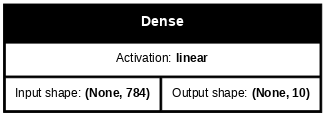

In [ ]:
plot_model(model, show_shapes=True, show_layer_names=False, show_layer_activations=True, dpi=64) # Graphical depiction of mode

Training the model. As with Sklearn, the fit function finds the parameters of the model that best fit the training data. Optionally, we can evaluate performance on the test (or validation) data as we train.

Results are similar to those of the Sklearn implementation.

Epoch 1/20
120/120 - 4s - 29ms/step - accuracy: 0.6631 - loss: 0.0762 - val_accuracy: 0.7839 - val_loss: 0.0549
Epoch 2/20
120/120 - 0s - 3ms/step - accuracy: 0.8039 - loss: 0.0513 - val_accuracy: 0.8315 - val_loss: 0.0476
Epoch 3/20
120/120 - 0s - 3ms/step - accuracy: 0.8209 - loss: 0.0477 - val_accuracy: 0.8332 - val_loss: 0.0458
Epoch 4/20
120/120 - 0s - 3ms/step - accuracy: 0.8280 - loss: 0.0460 - val_accuracy: 0.8353 - val_loss: 0.0436
Epoch 5/20
120/120 - 0s - 3ms/step - accuracy: 0.8328 - loss: 0.0449 - val_accuracy: 0.8384 - val_loss: 0.0439
Epoch 6/20
120/120 - 0s - 3ms/step - accuracy: 0.8335 - loss: 0.0442 - val_accuracy: 0.8347 - val_loss: 0.0432
Epoch 7/20
120/120 - 0s - 3ms/step - accuracy: 0.8355 - loss: 0.0436 - val_accuracy: 0.8479 - val_loss: 0.0432
Epoch 8/20
120/120 - 0s - 3ms/step - accuracy: 0.8392 - loss: 0.0432 - val_accuracy: 0.8485 - val_loss: 0.0433
Epoch 9/20
120/120 - 0s - 3ms/step - accuracy: 0.8396 - loss: 0.0429 - val_accuracy: 0.8426 - val_loss: 0.0423


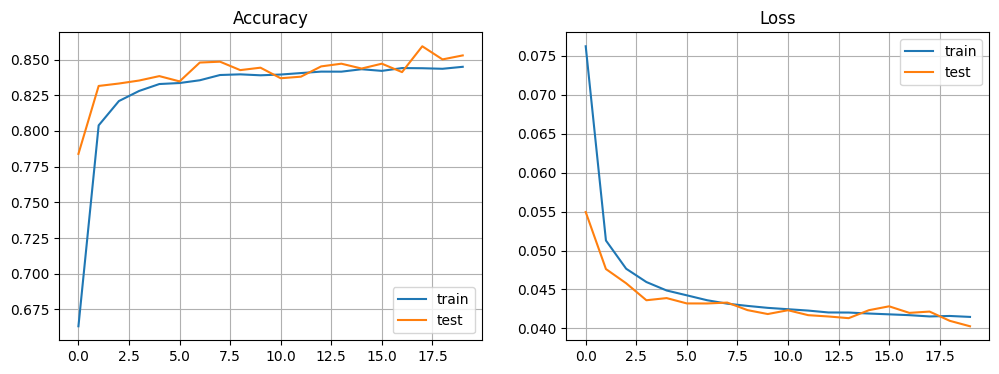

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Elapsed time training= 11.2346 secs
Accuracy = 0.8529
Confusion matrix
[[ 937    0    2    3    0    9   20    2    7    0]
 [   0 1111    3    4    2    1    5    1    8    0]
 [  23   71  777   26   11    1   51   30   34    8]
 [   6   17   16  890    3   13   15   25   16    9]
 [   0   28    5    1  860    8   17    2    8   53]
 [  22   17    2   76   16  670   31   16   29   13]
 [  19   10    4    0   11   15  897    0    2    0]
 [   6   39   13    7   17    2    2  892    0   50]
 [  15   61    9   45   20   54   32   16  697   25]
 [  18   13    3   18   59    4    3   88    5  798]]


In [ ]:
start_train = time.time()
history = model.fit(
    x_train, y_train,
    epochs = 20,
    batch_size = 500,
    verbose = 2, # Print loss and accuracy after evrey epoch. Set to 0 to see only final results
    validation_data=(x_test, y_test), # If provided, allows to keep track of loss on validation data as traiing progresses
)
end_train = time.time()
plot_results(history)
pred = model.predict(x_test)
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
pred_int = np.argmax(pred,axis=1)
print('Accuracy = {:.4f}'.format(accuracy_score(pred_int,np.argmax(y_test,axis=1))))
print('Confusion matrix')
print(confusion_matrix(np.argmax(y_test,axis=1), pred_int))


# **Logistic Regression**

We can add the softmax operation as an additional layer in the model.

In [ ]:
def logistic_regression(n_inputs, n_outputs):
  model = tf.keras.models.Sequential()
  model.add(Input((n_inputs,)))
  model.add(Dense(n_outputs))
  model.add(Softmax())
  # The dense and softmax operations can be combined into a single layer
  # model.add(Dense(n_outputs,activation = "softmax"))
  return model

Typically, we use the categorical cross entropy loss function, instead of mean-squared error.

Model: "sequential_32"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_55 (Dense)                │ (None, 10)             │         7,850 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax_6 (Softmax)             │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

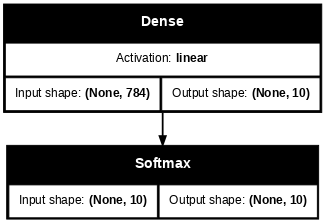

In [ ]:
model = logistic_regression(x_train.shape[1], y_train.shape[1])
model.summary()
model.compile(loss="CategoricalCrossentropy", metrics=["accuracy"])
plot_model(model, show_shapes=True, show_layer_names=False, show_layer_activations=True, dpi=64)

We will now fit the model. Again, results are similar to those obtained by Sklearn.

Epoch 1/20
120/120 - 4s - 37ms/step - accuracy: 0.7611 - loss: 0.9990 - val_accuracy: 0.8732 - val_loss: 0.5323
Epoch 2/20
120/120 - 0s - 3ms/step - accuracy: 0.8816 - loss: 0.4549 - val_accuracy: 0.9032 - val_loss: 0.3745
Epoch 3/20
120/120 - 0s - 3ms/step - accuracy: 0.9007 - loss: 0.3658 - val_accuracy: 0.9115 - val_loss: 0.3298
Epoch 4/20
120/120 - 0s - 3ms/step - accuracy: 0.9085 - loss: 0.3330 - val_accuracy: 0.9142 - val_loss: 0.3100
Epoch 5/20
120/120 - 0s - 3ms/step - accuracy: 0.9126 - loss: 0.3154 - val_accuracy: 0.9182 - val_loss: 0.2992
Epoch 6/20
120/120 - 0s - 3ms/step - accuracy: 0.9159 - loss: 0.3042 - val_accuracy: 0.9185 - val_loss: 0.2915
Epoch 7/20
120/120 - 0s - 3ms/step - accuracy: 0.9178 - loss: 0.2962 - val_accuracy: 0.9202 - val_loss: 0.2849
Epoch 8/20
120/120 - 0s - 3ms/step - accuracy: 0.9197 - loss: 0.2902 - val_accuracy: 0.9202 - val_loss: 0.2819
Epoch 9/20
120/120 - 0s - 3ms/step - accuracy: 0.9202 - loss: 0.2854 - val_accuracy: 0.9226 - val_loss: 0.2796


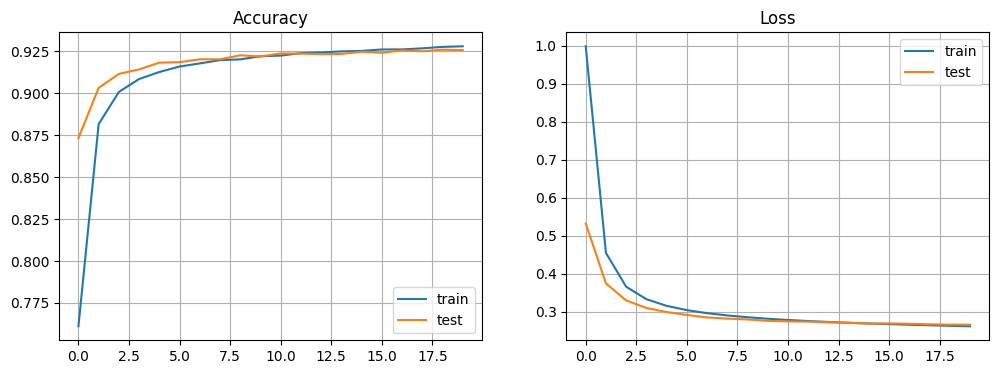

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Elapsed time training= 12.2277 secs
Accuracy = 0.9257
Confusion matrix
[[ 963    0    1    2    0    5    6    2    1    0]
 [   0 1111    3    2    0    1    4    2   12    0]
 [   5    9  922   19    9    4   12   10   38    4]
 [   2    0   19  929    0   20    2   12   19    7]
 [   2    1    5    1  917    0    9    3   10   34]
 [   9    2    3   40   11  770   14    5   32    6]
 [   9    3    6    1    8   14  912    2    3    0]
 [   1    5   21    8    9    0    0  948    2   34]
 [   5    6    7   24    9   25    9   12  870    7]
 [  11    7    1   11   32    6    0   21    5  915]]


In [ ]:
start_train = time.time()
history = model.fit(
    x_train, y_train,
    epochs = 40,
    batch_size = 1000,
    verbose = 2, # Print loss and accuracy after evrey epoch. Set to 0 to see only final results
    validation_data=(x_test, y_test), # If provided, allows to keep track of loss on validation data as traiing progresses
)
end_train = time.time()
plot_results(history)
pred = model.predict(x_test)
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
pred_int = np.argmax(pred,axis=1)
print('Accuracy = {:.4f}'.format(accuracy_score(pred_int,np.argmax(y_test,axis=1))))
print('Confusion matrix')
print(confusion_matrix(np.argmax(y_test,axis=1), pred_int))

# **Exercises**

## Exercise 1.

Evaluate the performance of linear regression with the addition of another dense layer after the input. You can select any number of output units; it be reasonable to choose a number between 10 and 784. Does the addition of a layer improve performance? Why?

Model: "sequential_25"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_43 (Dense)                │ (None, 500)            │       392,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 10)             │         5,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 397,510 (1.52 MB)

 Trainable params: 397,510 (1.52 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
300/300 - 6s - 19ms/step - accuracy: 0.5567 - loss: 0.1813 - val_accuracy: 0.8227 - val_loss: 0.0460
Epoch 2/20
300/300 - 1s - 3ms/step - accuracy: 0.8295 - loss: 0.0444 - val_accuracy: 0.8526 - val_loss: 0.0415
Epoch 3/20
300/300 - 1s - 3ms/step - accuracy: 0.8410 - loss: 0.0416 - val_accuracy: 0.8515 - val_loss: 0.0411
Epoch 4/20
300/300 - 1s - 3ms/step - accuracy: 0.8436 - loss: 0.0410 - val_accuracy: 0.8496 - val_loss: 0.0401
Epoch 5/20
300/300 - 1s - 3ms/step - accuracy: 0.8454 - loss: 0.0406 - val_accuracy: 0.8520 - val_loss: 0.0398
Epoch 6/20
300/300 - 1s - 3ms/step - accuracy: 0.8461 - loss: 0.0405 - val_accuracy: 0.8647 - val_loss: 0.0393
Epoch 7/20
300/300 - 1s - 3ms/step - accuracy: 0.8465 - loss: 0.0403 - val_accuracy: 0.8503 - val_loss: 0.0396
Epoch 8/20
300/300 - 1s - 2ms/step - accuracy: 0.8476 - loss: 0.0402 - val_accuracy: 0.8526 - val_loss: 0.0394
Epoch 9/20
300/300 - 1s - 2ms/step - accuracy: 0.8477 - loss: 0.0401 - val_accuracy: 0.8553 - val_loss: 0.0396


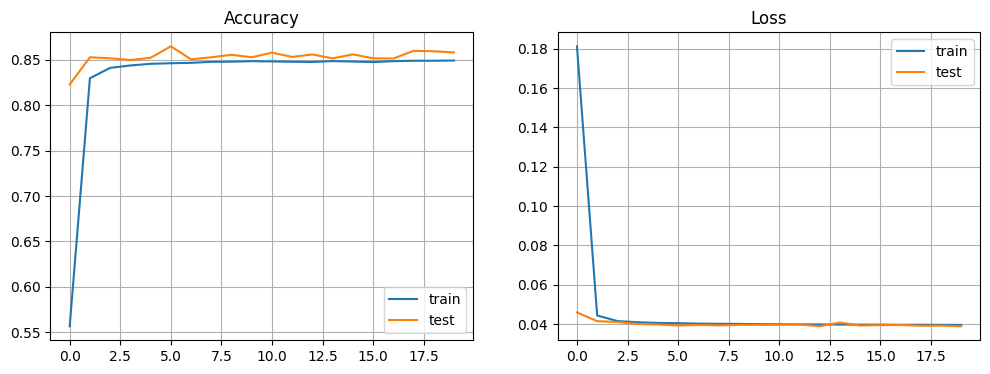

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Elapsed time training= 20.4066 secs
Accuracy = 0.8579
Confusion matrix
[[ 948    0    2    2    2    8    8    2    7    1]
 [   0 1103    4    1    2    1    5    0   18    1]
 [  18   48  845   16   16    0   29   15   38    7]
 [   8   20   32  857    4   14    6   20   32   17]
 [   1   23    6    0  868    3    8    1    8   64]
 [  27   15    6   80   23  625   20   14   59   23]
 [  24   11   20    0   23   21  849    0   10    0]
 [   6   44   18    6   23    0    1  865    0   65]
 [  12   41   11   22   22   40   15    7  777   27]
 [  17   10    3   14   57    1    1   57    7  842]]


In [ ]:
def model_1(n_inputs=784, hidden_units = 500, n_outputs=10):
  model = tf.keras.models.Sequential()
  model.add(Input((n_inputs,)))
  model.add(Dense(hidden_units))
  model.add(Dense(n_outputs))
  return model

model = model_1(x_train.shape[1], 500, y_train.shape[1])  # Create model with 784 inputs and 10 outputs
model.summary()                                                # Show model structure
model.compile(loss="mse", metrics=["accuracy"])

start_train = time.time()
history = model.fit(
    x_train, y_train,
    epochs = 40, # Perform 10 iterations over the whole dataset
    batch_size = 1000, # Split training data into groups of size 1000
    verbose = 2, # Print loss and accuracy after evrey epoch. Set to 0 to see only final results
    validation_data=(x_test, y_test), # If provided, allows to keep track of loss on validation data as traiing progresses
)
end_train = time.time()
plot_results(history)
pred = model.predict(x_test)
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
pred_int = np.argmax(pred,axis=1)
print('Accuracy = {:.4f}'.format(accuracy_score(pred_int,np.argmax(y_test,axis=1))))
print('Confusion matrix')
print(confusion_matrix(np.argmax(y_test,axis=1), pred_int))


## Exercise 2.

Evaluate the performance of logistic regression with the addition of another dense layer after the input. You can select any number of output units; it be reasonable to choose a number between 10 and 784. Does the addition of a layer improve performance? Why?

Model: "sequential_35"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_60 (Dense)                │ (None, 500)            │       392,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_61 (Dense)                │ (None, 10)             │         5,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 397,510 (1.52 MB)

 Trainable params: 397,510 (1.52 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
60/60 - 7s - 110ms/step - accuracy: 0.8304 - loss: 0.5777 - val_accuracy: 0.8940 - val_loss: 0.3625
Epoch 2/40
60/60 - 0s - 5ms/step - accuracy: 0.8992 - loss: 0.3447 - val_accuracy: 0.9093 - val_loss: 0.3189
Epoch 3/40
60/60 - 0s - 5ms/step - accuracy: 0.9087 - loss: 0.3190 - val_accuracy: 0.9182 - val_loss: 0.2855
Epoch 4/40
60/60 - 0s - 5ms/step - accuracy: 0.9127 - loss: 0.3035 - val_accuracy: 0.9194 - val_loss: 0.2835
Epoch 5/40
60/60 - 0s - 5ms/step - accuracy: 0.9160 - loss: 0.2982 - val_accuracy: 0.9161 - val_loss: 0.2929
Epoch 6/40
60/60 - 0s - 5ms/step - accuracy: 0.9182 - loss: 0.2905 - val_accuracy: 0.9235 - val_loss: 0.2747
Epoch 7/40
60/60 - 0s - 5ms/step - accuracy: 0.9202 - loss: 0.2848 - val_accuracy: 0.9195 - val_loss: 0.2826
Epoch 8/40
60/60 - 0s - 5ms/step - accuracy: 0.9187 - loss: 0.2860 - val_accuracy: 0.9207 - val_loss: 0.2798
Epoch 9/40
60/60 - 0s - 5ms/step - accuracy: 0.9216 - loss: 0.2783 - val_accuracy: 0.9213 - val_loss: 0.2791
Epoch 10/40
60/60

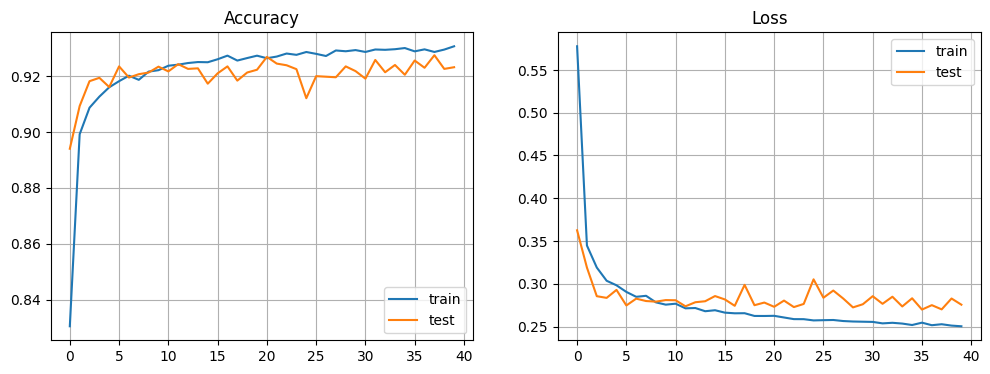

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Elapsed time training= 17.7619 secs
Accuracy = 0.9232
Confusion matrix
[[ 956    0    1    3    3    6    5    4    2    0]
 [   0 1112    3    2    1    1    4    2   10    0]
 [   3   10  919   13   14    6   13    8   40    6]
 [   2    0   17  912    7   28    2   10   20   12]
 [   1    1    5    3  941    0    5    0    7   19]
 [   8    3    3   27   15  788   15    4   25    4]
 [   9    3    9    1   10   18  906    2    0    0]
 [   1    5   22    4   12    1    0  942    2   39]
 [   6    9    6   19   14   31   10    7  859   13]
 [   6    6    3    8   56    8    0   15   10  897]]


In [ ]:
def model_2a(n_inputs=784, hidden_units = 500, n_outputs=10):
  model = tf.keras.models.Sequential()
  model.add(Input((n_inputs,)))
  model.add(Dense(hidden_units))
  model.add(Dense(n_outputs, activation = 'softmax'))
  return model

model = model_2a(x_train.shape[1], 500, y_train.shape[1])  # Create model with 784 inputs and 10 outputs
model.summary()                                                # Show model structure
model.compile(loss="CategoricalCrossentropy", metrics=["accuracy"])

start_train = time.time()
history = model.fit(
    x_train, y_train,
    epochs = 40, # Perform 10 iterations over the whole dataset
    batch_size = 1000, # Split training data into groups of size 1000
    verbose = 2, # Print loss and accuracy after evrey epoch. Set to 0 to see only final results
    validation_data=(x_test, y_test), # If provided, allows to keep track of loss on validation data as traiing progresses
)
end_train = time.time()
plot_results(history)
pred = model.predict(x_test)
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
pred_int = np.argmax(pred,axis=1)
print('Accuracy = {:.4f}'.format(accuracy_score(pred_int,np.argmax(y_test,axis=1))))
print('Confusion matrix')
print(confusion_matrix(np.argmax(y_test,axis=1), pred_int))


Now add a softmax activation to the new 'hidden' layer.

Model: "sequential_37"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_64 (Dense)                │ (None, 500)            │       392,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_65 (Dense)                │ (None, 10)             │         5,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 397,510 (1.52 MB)

 Trainable params: 397,510 (1.52 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
60/60 - 2s - 40ms/step - accuracy: 0.1178 - loss: 2.3008 - val_accuracy: 0.1135 - val_loss: 2.2989
Epoch 2/40
60/60 - 0s - 4ms/step - accuracy: 0.1137 - loss: 2.2966 - val_accuracy: 0.1467 - val_loss: 2.2893
Epoch 3/40
60/60 - 0s - 4ms/step - accuracy: 0.2818 - loss: 2.2546 - val_accuracy: 0.3133 - val_loss: 2.2218
Epoch 4/40
60/60 - 0s - 4ms/step - accuracy: 0.3511 - loss: 2.1880 - val_accuracy: 0.3930 - val_loss: 2.1442
Epoch 5/40
60/60 - 0s - 5ms/step - accuracy: 0.4008 - loss: 2.0991 - val_accuracy: 0.3877 - val_loss: 2.0529
Epoch 6/40
60/60 - 0s - 5ms/step - accuracy: 0.3983 - loss: 2.0122 - val_accuracy: 0.3899 - val_loss: 1.9733
Epoch 7/40
60/60 - 0s - 5ms/step - accuracy: 0.3972 - loss: 1.9387 - val_accuracy: 0.3921 - val_loss: 1.9045
Epoch 8/40
60/60 - 0s - 4ms/step - accuracy: 0.3965 - loss: 1.8733 - val_accuracy: 0.3931 - val_loss: 1.8421
Epoch 9/40
60/60 - 0s - 4ms/step - accuracy: 0.3974 - loss: 1.8135 - val_accuracy: 0.3943 - val_loss: 1.7845
Epoch 10/40
60/60 

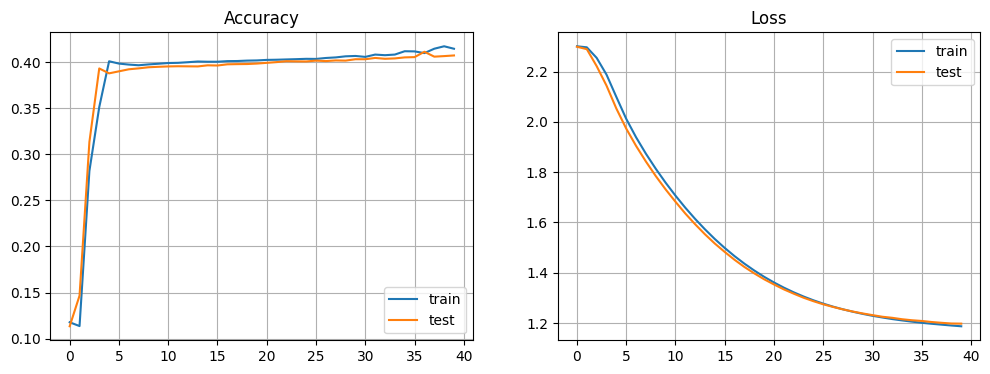

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Elapsed time training= 13.3485 secs
Accuracy = 0.4071
Confusion matrix
[[   0    0   19  951    0    0    2    3    2    3]
 [   0 1117    4    4    0    0    3    1    5    1]
 [   0    4  136   82    8    0  765    8   24    5]
 [   0    1   19  955    1    0    4    8   13    9]
 [   0    0   17    7   21    0   10  900    2   25]
 [   0    4   13  849    0    0    6    4    5   11]
 [   0    3   83   32    1    0  824    4   11    0]
 [   0   13   11   20    8    0    5  938    3   30]
 [   0    9   23  879    0    0    6    8   32   17]
 [   0    7    1   43    3    0    1  902    4   48]]


In [ ]:
def model_2b(n_inputs=784, hidden_units = 500, n_outputs=10):
  model = tf.keras.models.Sequential()
  model.add(Input((n_inputs,)))
  model.add(Dense(hidden_units, activation='softmax'))
  model.add(Dense(n_outputs, activation = 'softmax'))
  return model

model = model_2b(x_train.shape[1], 500, y_train.shape[1])  # Create model with 784 inputs and 10 outputs
model.summary()                                                # Show model structure
model.compile(loss="CategoricalCrossentropy", metrics=["accuracy"])

start_train = time.time()
history = model.fit(
    x_train, y_train,
    epochs = 40, # Perform 10 iterations over the whole dataset
    batch_size = 1000, # Split training data into groups of size 1000
    verbose = 2, # Print loss and accuracy after evrey epoch. Set to 0 to see only final results
    validation_data=(x_test, y_test), # If provided, allows to keep track of loss on validation data as traiing progresses
)
end_train = time.time()
plot_results(history)
pred = model.predict(x_test)
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
pred_int = np.argmax(pred,axis=1)
print('Accuracy = {:.4f}'.format(accuracy_score(pred_int,np.argmax(y_test,axis=1))))
print('Confusion matrix')
print(confusion_matrix(np.argmax(y_test,axis=1), pred_int))


Using sigmoid activation for the hidden layer

Model: "sequential_38"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_66 (Dense)                │ (None, 500)            │       392,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_67 (Dense)                │ (None, 10)             │         5,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 397,510 (1.52 MB)

 Trainable params: 397,510 (1.52 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
60/60 - 3s - 58ms/step - accuracy: 0.7849 - loss: 0.9766 - val_accuracy: 0.8759 - val_loss: 0.5122
Epoch 2/40
60/60 - 0s - 5ms/step - accuracy: 0.8838 - loss: 0.4449 - val_accuracy: 0.9026 - val_loss: 0.3637
Epoch 3/40
60/60 - 0s - 5ms/step - accuracy: 0.8993 - loss: 0.3611 - val_accuracy: 0.9097 - val_loss: 0.3213
Epoch 4/40
60/60 - 0s - 5ms/step - accuracy: 0.9069 - loss: 0.3260 - val_accuracy: 0.9151 - val_loss: 0.2992
Epoch 5/40
60/60 - 0s - 5ms/step - accuracy: 0.9119 - loss: 0.3045 - val_accuracy: 0.9161 - val_loss: 0.2860
Epoch 6/40
60/60 - 0s - 5ms/step - accuracy: 0.9164 - loss: 0.2903 - val_accuracy: 0.9204 - val_loss: 0.2769
Epoch 7/40
60/60 - 0s - 5ms/step - accuracy: 0.9204 - loss: 0.2777 - val_accuracy: 0.9226 - val_loss: 0.2637
Epoch 8/40
60/60 - 0s - 5ms/step - accuracy: 0.9234 - loss: 0.2662 - val_accuracy: 0.9273 - val_loss: 0.2547
Epoch 9/40
60/60 - 0s - 5ms/step - accuracy: 0.9261 - loss: 0.2549 - val_accuracy: 0.9306 - val_loss: 0.2455
Epoch 10/40
60/60 

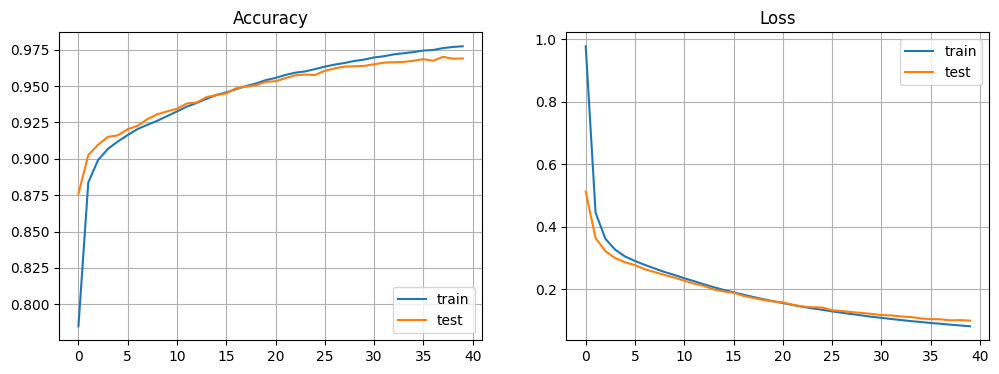

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Elapsed time training= 14.5618 secs
Accuracy = 0.9690
Confusion matrix
[[ 967    0    1    1    0    4    3    1    1    2]
 [   0 1125    2    1    0    1    4    1    1    0]
 [   6    1  998    4    2    0    3    8    9    1]
 [   0    0    1  992    0    1    0    7    5    4]
 [   1    0    4    1  930    0    8    3    2   33]
 [   7    1    0   16    2  846    8    3    6    3]
 [   7    3    1    1    2    5  933    2    4    0]
 [   0    9    9    4    0    1    0  992    0   13]
 [   3    2    4   11    3    5    3    6  934    3]
 [   5    6    1    9    6    2    0    6    1  973]]


In [ ]:
def model_2c(n_inputs=784, hidden_units = 500, n_outputs=10):
  model = tf.keras.models.Sequential()
  model.add(Input((n_inputs,)))
  model.add(Dense(hidden_units, activation='sigmoid'))
  model.add(Dense(n_outputs, activation = 'softmax'))
  return model

model = model_2c(x_train.shape[1], 500, y_train.shape[1])  # Create model with 784 inputs and 10 outputs
model.summary()                                                # Show model structure
model.compile(loss="CategoricalCrossentropy", metrics=["accuracy"])

start_train = time.time()
history = model.fit(
    x_train, y_train,
    epochs = 40, # Perform 10 iterations over the whole dataset
    batch_size = 1000, # Split training data into groups of size 1000
    verbose = 2, # Print loss and accuracy after evrey epoch. Set to 0 to see only final results
    validation_data=(x_test, y_test), # If provided, allows to keep track of loss on validation data as traiing progresses
)
end_train = time.time()
plot_results(history)
pred = model.predict(x_test)
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
pred_int = np.argmax(pred,axis=1)
print('Accuracy = {:.4f}'.format(accuracy_score(pred_int,np.argmax(y_test,axis=1))))
print('Confusion matrix')
print(confusion_matrix(np.argmax(y_test,axis=1), pred_int))


Using relu activation for the hidden layer

Model: "sequential_41"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_72 (Dense)                │ (None, 500)            │       392,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_73 (Dense)                │ (None, 10)             │         5,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 397,510 (1.52 MB)

 Trainable params: 397,510 (1.52 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
60/60 - 3s - 57ms/step - accuracy: 0.8511 - loss: 0.5433 - val_accuracy: 0.9244 - val_loss: 0.2734
Epoch 2/40
60/60 - 0s - 5ms/step - accuracy: 0.9273 - loss: 0.2564 - val_accuracy: 0.9422 - val_loss: 0.2020
Epoch 3/40
60/60 - 0s - 5ms/step - accuracy: 0.9462 - loss: 0.1894 - val_accuracy: 0.9507 - val_loss: 0.1666
Epoch 4/40
60/60 - 0s - 5ms/step - accuracy: 0.9578 - loss: 0.1498 - val_accuracy: 0.9603 - val_loss: 0.1340
Epoch 5/40
60/60 - 0s - 5ms/step - accuracy: 0.9649 - loss: 0.1236 - val_accuracy: 0.9610 - val_loss: 0.1247
Epoch 6/40
60/60 - 0s - 5ms/step - accuracy: 0.9705 - loss: 0.1046 - val_accuracy: 0.9676 - val_loss: 0.1092
Epoch 7/40
60/60 - 0s - 5ms/step - accuracy: 0.9743 - loss: 0.0900 - val_accuracy: 0.9735 - val_loss: 0.0913
Epoch 8/40
60/60 - 0s - 5ms/step - accuracy: 0.9782 - loss: 0.0780 - val_accuracy: 0.9726 - val_loss: 0.0903
Epoch 9/40
60/60 - 0s - 5ms/step - accuracy: 0.9804 - loss: 0.0696 - val_accuracy: 0.9751 - val_loss: 0.0809
Epoch 10/40
60/60 

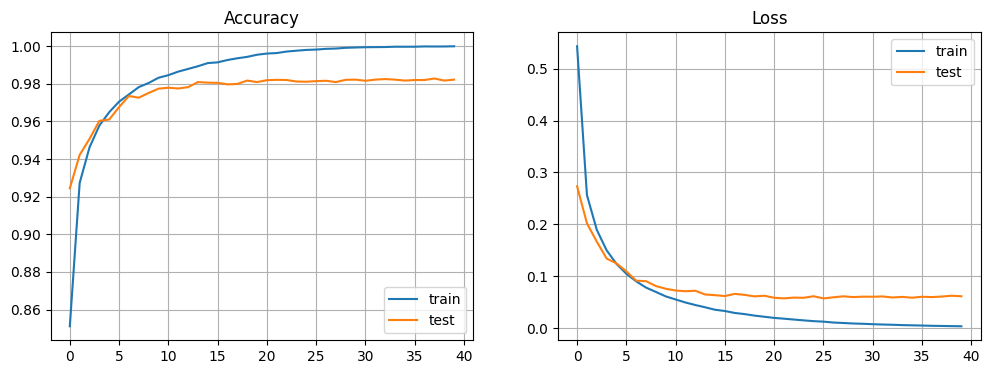

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Elapsed time training= 14.6228 secs
Accuracy = 0.9822
Confusion matrix
[[ 972    0    1    0    0    0    3    1    2    1]
 [   0 1126    3    1    0    1    2    1    1    0]
 [   3    3 1010    1    2    0    3    6    3    1]
 [   0    0    3  993    0    3    0    3    2    6]
 [   1    0    2    1  967    0    3    2    0    6]
 [   2    0    0    6    0  874    3    2    3    2]
 [   4    3    2    1    2    2  943    0    1    0]
 [   2    5    5    2    0    0    0 1010    1    3]
 [   7    2    3    3    4    2    3    3  943    4]
 [   2    3    0    4    8    3    1    4    0  984]]


In [ ]:
def model_2d(n_inputs=784, hidden_units = 500, n_outputs=10):
  model = tf.keras.models.Sequential()
  model.add(Input((n_inputs,)))
  model.add(Dense(hidden_units, activation='relu'))
  model.add(Dense(n_outputs, activation = 'softmax'))
  return model

model = model_2d(x_train.shape[1], 500, y_train.shape[1])  # Create model with 784 inputs and 10 outputs
model.summary()                                                # Show model structure
model.compile(loss="CategoricalCrossentropy", metrics=["accuracy"])

start_train = time.time()
history = model.fit(
    x_train, y_train,
    epochs = 40,
    batch_size = 1000,
    verbose = 2, # Print loss and accuracy after evrey epoch. Set to 0 to see only final results
    validation_data=(x_test, y_test), # If provided, allows to keep track of loss on validation data as traiing progresses
)
end_train = time.time()
plot_results(history)
pred = model.predict(x_test)
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
pred_int = np.argmax(pred,axis=1)
print('Accuracy = {:.4f}'.format(accuracy_score(pred_int,np.argmax(y_test,axis=1))))
print('Confusion matrix')
print(confusion_matrix(np.argmax(y_test,axis=1), pred_int))


Model: "sequential_42"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_74 (Dense)                │ (None, 500)            │       392,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_75 (Dense)                │ (None, 500)            │       250,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_76 (Dense)                │ (None, 10)             │         5,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 648,010 (2.47 MB)

 Trainable params: 648,010 (2.47 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
60/60 - 4s - 72ms/step - accuracy: 0.8360 - loss: 0.5318 - val_accuracy: 0.9262 - val_loss: 0.2472
Epoch 2/40
60/60 - 0s - 5ms/step - accuracy: 0.9378 - loss: 0.2046 - val_accuracy: 0.9444 - val_loss: 0.1763
Epoch 3/40
60/60 - 0s - 5ms/step - accuracy: 0.9575 - loss: 0.1399 - val_accuracy: 0.9680 - val_loss: 0.1046
Epoch 4/40
60/60 - 0s - 5ms/step - accuracy: 0.9691 - loss: 0.1021 - val_accuracy: 0.9670 - val_loss: 0.1014
Epoch 5/40
60/60 - 0s - 5ms/step - accuracy: 0.9755 - loss: 0.0813 - val_accuracy: 0.9732 - val_loss: 0.0844
Epoch 6/40
60/60 - 0s - 5ms/step - accuracy: 0.9802 - loss: 0.0654 - val_accuracy: 0.9776 - val_loss: 0.0702
Epoch 7/40
60/60 - 0s - 5ms/step - accuracy: 0.9838 - loss: 0.0529 - val_accuracy: 0.9733 - val_loss: 0.0823
Epoch 8/40
60/60 - 0s - 5ms/step - accuracy: 0.9869 - loss: 0.0435 - val_accuracy: 0.9777 - val_loss: 0.0691
Epoch 9/40
60/60 - 0s - 5ms/step - accuracy: 0.9889 - loss: 0.0366 - val_accuracy: 0.9800 - val_loss: 0.0594
Epoch 10/40
60/60 

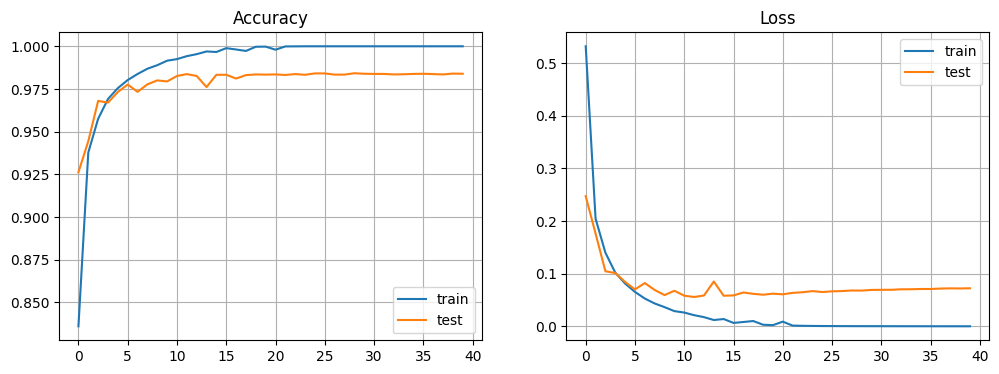

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
Elapsed time training= 15.5848 secs
Accuracy = 0.9839
Confusion matrix
[[ 969    1    1    0    2    1    2    1    2    1]
 [   0 1126    2    1    0    1    2    1    2    0]
 [   1    1 1014    1    1    0    2    6    5    1]
 [   0    0    4  992    0    2    0    3    3    6]
 [   1    0    2    1  967    0    3    2    0    6]
 [   2    0    0    6    1  872    4    1    4    2]
 [   2    2    0    1    5    3  944    0    1    0]
 [   0    2    7    0    0    0    0 1012    3    4]
 [   2    0    3    3    2    1    3    3  953    4]
 [   2    2    0    3    7    1    0    4    0  990]]


In [ ]:
def model_2d(n_inputs=784, hidden_units = 500, n_outputs=10):
  model = tf.keras.models.Sequential()
  model.add(Input((n_inputs,)))
  model.add(Dense(hidden_units, activation='relu'))
  model.add(Dense(hidden_units, activation='relu'))
  model.add(Dense(n_outputs, activation = 'softmax'))
  return model

model = model_2d(x_train.shape[1], 500, y_train.shape[1])  # Create model with 784 inputs and 10 outputs
model.summary()                                                # Show model structure
model.compile(loss="CategoricalCrossentropy", metrics=["accuracy"])

start_train = time.time()
history = model.fit(
    x_train, y_train,
    epochs = 40,
    batch_size = 1000,
    verbose = 2, # Print loss and accuracy after evrey epoch. Set to 0 to see only final results
    validation_data=(x_test, y_test), # If provided, allows to keep track of loss on validation data as traiing progresses
)
end_train = time.time()
plot_results(history)
pred = model.predict(x_test)
print('Elapsed time training= {:.4f} secs'.format(end_train-start_train))
pred_int = np.argmax(pred,axis=1)
print('Accuracy = {:.4f}'.format(accuracy_score(pred_int,np.argmax(y_test,axis=1))))
print('Confusion matrix')
print(confusion_matrix(np.argmax(y_test,axis=1), pred_int))